# Can d_B stop following the variances?

**Why it does.** For counts a gene's variance follows its mean, so ‖log Σ_q − log Σ_t‖ mostly compares per-gene log
variances, an expression distance in disguise (Spearman 0.79 with the variance distance, −0.16 with the correlation
distance). Cell size adds a second, technical co-variation: a bigger cell has more of every transcript.
`beyond_expression.ipynb` and `rerank.ipynb` (30 Oct) found correlation-only blind to composition and size-normalised
counts the best trade-off. This notebook tests variants that remove one cause or re-weight the terms.

| Variant | Tile covariance computed on |
|---|---|
| d_B (the method) | raw counts |
| d_B size-normalised | counts × (median cell total / cell total) |
| d_B log-normalised | log1p of size-normalised counts |
| d_B Pearson residuals | analytic Pearson residuals (Lause et al. 2021): μ = cell total × gene share, θ = 100, clipped at ±√N |
| d_B within-cluster | log-normalised counts minus the mean of the cell's k-means cluster (20 clusters on 30 PCs, no annotations) |
| Mix λ (raw or Pearson) | √(λ·d_var² + (w·d_corr)²) on that covariance; w = median d_var / median d_corr; λ = 0 is correlation only, λ = 1 equal weight |

Each covariance variant gets its own production layout (niches and blocks built from its covariances); the mixes use
their base's layout. Baselines: Expression (‖log1p μ_q − log1p μ_t‖/√p) and Variance only (raw).

**Tests** (breast, quadtree cap 200 = production, seeds 0–4, 10 % held out):
1. **Size-preserving decoy, half and half.** B̃ = half B with every gene's raw values shuffled among the cells of
   the same annotated type *and* the same size quartile (of total counts, within the type). B̃ keeps composition,
   means and variances exactly and most cell-size co-variation, and loses within-type co-expression.
   Win = d(A, B) < d(A, B̃); 0.5 = blind. (The 30 Oct decoy shuffled within type only, which also destroyed cell
   size and inflated d_B's 0.97. A first version of this run shuffled size-normalised values and restored sizes;
   that shifted the raw means, so expression won 91 %, and it was replaced.)
2. **Decoy rank.** The full held-out tile Q and its size-preserving decoy: the share of index tiles closer to Q than
   Q̃ is. 0 = the decoy is the nearest; higher = co-expression changes who the neighbours are.
3. **Composition lift of the top 10** (the cost: cell-class similarity to Q minus that of random tiles). The
   *oracle* (the 10 index tiles closest to Q in composition itself) gives the ceiling at this tile size.
4. **Held-out co-expression after re-ranking** (as `rerank.ipynb`): half A queries; each distance picks 10 of
   expression's 50 nearest; score = agreement of within-type co-expression with half B, minus expression's own top 10.
5. **Variance dominance.** Per query, Spearman of each distance with the raw variance-only and correlation-only
   distances over all index tiles.

**Pass rule, fixed before the run:** test 1 ≥ 0.70, test 2 ≥ 0.10 and test 3 ≥ 0.40 (d_B: 0.443), mean over seeds.

Experiment code only; `src/` is unchanged.

In [1]:
import logging
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import spearmanr, wilcoxon
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

ROOT = Path.cwd().resolve()
while not (ROOT / "datasets.yaml").exists():
    ROOT = ROOT.parent
for p in (ROOT / "src", ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import paths
import spindle_dev as sd
from spindle_dev.metrics import shrink_cov, spd_to_correlation
from spindle_dev.preprocessing import build_quadtree_tiles, topvar_genes
from spindle_dev.naive import BlockVectorizer

logging.getLogger("spindle_dev").setLevel(logging.WARNING)
KEY, SEEDS, TEST_RATIO, CAP = "breast_cancer", [0, 1, 2, 3, 4], 0.1, 200
TOP, N_CAND = 10, 50
DETECT, MIN_GENES = 0.10, 10      # co-expression agreement: gene on in >= 10 % of cells, >= 10 genes on in both
THETA, N_CLUST = 100.0, 20
LAMBDAS = [0.0, 0.1, 0.3, 1.0]
BASES = ["raw", "size-normalised", "log-normalised", "Pearson residuals", "within-cluster"]
METHODS = (["Expression", "Variance only"] + [f"d_B {b}" for b in BASES]
           + [f"Mix raw λ={l}" for l in LAMBDAS] + [f"Mix Pearson λ={l}" for l in LAMBDAS])
PASS = {"half win": 0.70, "decoy rank": 0.10, "composition lift": 0.40}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## Data and cell transforms

In [2]:
adata = sd.load_adata(paths.dataset_path(KEY))
max_genes = paths.dataset_max_genes(KEY)
genes, gene_idx = topvar_genes(adata, G=min(max_genes, adata.n_vars))
genes = np.asarray(genes).astype(str)
p = len(genes)
Xg = adata.X[:, gene_idx]
Xg = Xg.tocsr() if sp.issparse(Xg) else sp.csr_matrix(Xg)
xy = np.asarray(adata.obsm["spatial"], dtype=np.float64)
lib = np.asarray(adata.X.sum(1)).ravel().astype(np.float64)
scale = np.median(lib) / np.maximum(lib, 1)                        # per-cell size normalisation
share = np.asarray(Xg.sum(0)).ravel() / lib.sum()                  # Pearson residuals: gene share of all counts
CLIP = np.sqrt(adata.n_obs)

fine_id = np.unique(adata.obs["Cluster"].astype(str).to_numpy(), return_inverse=True)[1]
CLASSES = [
    ("Invasive tumour", ["Invasive_Tumor", "Prolif_Invasive_Tumor", "T_Cell_&_Tumor_Hybrid"]),
    ("DCIS", ["DCIS_1", "DCIS_2"]),
    ("Myoepithelial", ["Myoepi_ACTA2+", "Myoepi_KRT15+"]),
    ("Stromal", ["Stromal", "Stromal_&_T_Cell_Hybrid"]),
    ("Endothelial / perivascular", ["Endothelial", "Perivascular-Like"]),
    ("Myeloid", ["Macrophages_1", "Macrophages_2", "IRF7+_DCs", "LAMP3+_DCs", "Mast_Cells"]),
    ("T cells", ["CD4+_T_Cells", "CD8+_T_Cells"]),
    ("B cells", ["B_Cells"]),
]
to_class = {t: i for i, (_, members) in enumerate(CLASSES) for t in members}
cell_cls = np.array([to_class[t] for t in adata.obs["Cluster"].astype(str)])
NC = len(CLASSES)
# decoy strata: annotated type x quartile of the cell's total count within its type (over the section)
size_q = np.zeros(adata.n_obs, dtype=int)
for t in np.unique(fine_id):
    r = np.flatnonzero(fine_id == t)
    size_q[r] = np.searchsorted(np.quantile(lib[r], [0.25, 0.5, 0.75]), lib[r], side="right")
size_stratum = fine_id * 4 + size_q

# annotation-free clusters for the within-cluster variant: k-means on 30 PCs of log-normalised counts
L_all = np.log1p(Xg.multiply(scale[:, None]).toarray())
clust = KMeans(N_CLUST, n_init=4, random_state=0).fit_predict(PCA(30, random_state=0).fit_transform(L_all))
clust_mean = np.stack([L_all[clust == c].mean(0) for c in range(N_CLUST)])
del L_all
print(f"{adata.n_obs} cells, {p} genes, {len(np.unique(fine_id))} annotated types, {N_CLUST} k-means clusters")


def cells(idx):
    return Xg[idx].toarray().astype(np.float64)


def transform(X, idx, base):
    # the cell matrix a variant's covariance is computed on
    if base == "raw":
        return X
    if base == "size-normalised":
        return X * scale[idx, None]
    if base == "log-normalised":
        return np.log1p(X * scale[idx, None])
    if base == "Pearson residuals":
        mu = lib[idx, None] * share[None, :]
        return np.clip((X - mu) / np.sqrt(mu + mu ** 2 / THETA + 1e-12), -CLIP, CLIP)
    if base == "within-cluster":
        return np.log1p(X * scale[idx, None]) - clust_mean[clust[idx]]
    raise ValueError(base)


def cov_of(Z):
    # as preprocessing._tile_cov: ML covariance + 1e-6 on the diagonal, then shrunk once (alpha = 0.1)
    mu = Z.mean(0)
    S = Z.T @ Z / Z.shape[0] - np.outer(mu, mu)
    S.flat[::p + 1] += 1e-6
    return shrink_cov(S)


def decoy(X, idx, rng):
    # size-preserving: shuffle every gene's raw values among the cells of the same annotated type and size quartile;
    # keeps composition, means and variances exactly, and most cell-size co-variation
    Y = X.copy()
    strata = size_stratum[idx]
    for t in np.unique(strata):
        r = np.flatnonzero(strata == t)
        if r.size > 1:
            Y[r] = X[r][np.argsort(rng.random((r.size, p)), axis=0), np.arange(p)]
    return Y


def coexpression(idx):
    # within-type co-expression of a cell set (as rerank.ipynb): size-normalised log1p, type means removed
    X = cells(idx)
    Z = np.log1p(X * scale[idx, None])
    types = fine_id[idx]
    for t in np.unique(types):
        r = types == t
        Z[r] -= Z[r].mean(0)
    on = ((X > 0).mean(0) >= DETECT) & (Z.std(0) > 0)
    R = np.zeros((p, p), dtype=np.float32)
    g = np.flatnonzero(on)
    if g.size >= 2:
        R[np.ix_(g, g)] = np.corrcoef(Z[:, g].T)
    return R, on


def agreement(Ra, on_a, Rb, on_b):
    g = np.flatnonzero(on_a & on_b)
    if g.size < MIN_GENES:
        return np.nan
    iu = np.triu_indices(g.size, 1)
    return np.corrcoef(Ra[np.ix_(g, g)][iu], Rb[np.ix_(g, g)][iu])[0, 1]


def composition(idx):
    c = np.bincount(cell_cls[idx], minlength=NC).astype(float)
    return c / max(c.sum(), 1)


def tv_sim(a, b):
    return 1 - 0.5 * np.abs(a - b).sum(-1)

159226 cells, 313 genes, 19 annotated types, 20 k-means clusters


## Tiles and covariances (once; each variant's index covariances do not depend on the seed)

In [3]:
tiles = build_quadtree_tiles(xy, max_pts=CAP, min_side=0.0, max_depth=40)
K = len(tiles)
X_t = [cells(t.idx) for t in tiles]
COV = {b: [cov_of(transform(X, t.idx, b)).astype(np.float32) for X, t in zip(X_t, tiles)] for b in BASES}
comp = np.stack([composition(t.idx) for t in tiles])
CO = [coexpression(t.idx) for t in tiles]
logmu = np.stack([np.log1p(X.mean(0)) for X in X_t]) / np.sqrt(p)
med_cells = int(np.median([t.idx.size for t in tiles]))
print(f"{K} tiles, median {med_cells} cells")

[2026-11-01 05:07:24,536] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 37 low-density tile(s) (1865 spots)


2044 tiles, median 67 cells


## Run

In [4]:
def features(Z, VEC, niches):
    # one variant's features of a cell matrix: log variances and, in the given niches, the d_B and correlation vectors
    C = cov_of(Z)
    R = spd_to_correlation(C)
    return {"var": np.log(np.diag(C)) / np.sqrt(p),
            "dB": {k: VEC[k].vector(C) for k in niches}, "corr": {k: VEC[k].vector(R) for k in niches}}


def all_features(X, idx, niches_of):
    # every variant's features; niches_of[b] = the niches in which b's vectors are needed
    return {b: features(transform(X, idx, b), L[b]["VEC"], niches_of[b]) for b in BASES}


def method_dist(m, var, dB, corr):
    # one method's distance from its components (arrays or scalars) for the bases it uses
    if m.startswith("d_B "):
        return dB[m[4:]]
    base = "raw" if m.startswith("Mix raw") else "Pearson residuals"
    lam = float(m.split("=")[1])
    return np.sqrt(lam * var[base] ** 2 + (L[base]["W"] * corr[base]) ** 2)


def to_index(F):
    # distances from one query (features in every niche) to all index tiles, per method
    var, dB, corr = {}, {}, {}
    for b in BASES:
        I = L[b]
        var[b] = np.linalg.norm(I["var"] - F[b]["var"], axis=1)
        dB[b], corr[b] = np.empty(len(train)), np.empty(len(train))
        for k, rows in I["rows"].items():
            dB[b][rows] = np.linalg.norm(I["dB"][k] - F[b]["dB"][k], axis=1)
            corr[b][rows] = np.linalg.norm(I["corr"][k] - F[b]["corr"][k], axis=1)
    return var, dB, corr


def pair(Fa, Fb, kq):
    # component distances between two feature sets, in each base's query niche kq[b]
    var = {b: np.linalg.norm(Fa[b]["var"] - Fb[b]["var"]) for b in BASES}
    dB = {b: np.linalg.norm(Fa[b]["dB"][kq[b]] - Fb[b]["dB"][kq[b]]) for b in BASES}
    corr = {b: np.linalg.norm(Fa[b]["corr"][kq[b]] - Fb[b]["corr"][kq[b]]) for b in BASES}
    return var, dB, corr


RES = []
for seed in SEEDS:
    rng = np.random.default_rng(seed)
    train, test = sd.split_tiles(K, seed=seed, test_ratio=TEST_RATIO)
    test = np.array([q for q in test if tiles[q].idx.size >= 20])
    L = {}
    for b in BASES:
        layout = sd.build_layout([tiles[i] for i in train], [{"tile_id": i, "cov": COV[b][i]} for i in train],
                                 genes, adata.n_obs)
        labels = np.asarray(layout.labels).astype(int)
        rows = {k: np.flatnonzero(labels == k) for k in sorted(set(labels.tolist()))}
        VEC = {k: BlockVectorizer(layout.perm_list[k], layout.block_dict[k]) for k in rows}
        C = {k: [COV[b][train[r]].astype(np.float64) for r in rs] for k, rs in rows.items()}
        L[b] = {"rows": rows, "label": labels, "VEC": VEC, "W": 1.0,
                "var": np.stack([np.log(np.diag(COV[b][i].astype(np.float64))) for i in train]) / np.sqrt(p),
                "dB": {k: np.stack([VEC[k].vector(c) for c in C[k]]) for k in rows},
                "corr": {k: np.stack([VEC[k].vector(spd_to_correlation(c)) for c in C[k]]) for k in rows}}
    ALL = {b: list(L[b]["rows"]) for b in BASES}
    FQ = {q: all_features(X_t[q], tiles[q].idx, ALL) for q in test}
    # equal-weight scale of the mixes: median d_var / median d_corr over 50 queries x index
    comps = [to_index(FQ[q]) for q in test[:50]]
    for b in ("raw", "Pearson residuals"):
        L[b]["W"] = np.median(np.concatenate([c[0][b] for c in comps])) / np.median(np.concatenate([c[2][b] for c in comps]))

    for q in test:
        idx, X = tiles[q].idx, X_t[q]
        var, dB, corr = to_index(FQ[q])
        D = {"Expression": np.linalg.norm(logmu[train] - logmu[q], axis=1), "Variance only": var["raw"]}
        D.update({m: method_dist(m, var, dB, corr) for m in METHODS[2:]})
        # each base's query niche: that of its nearest index tile under its own d_B
        kq = {b: int(L[b]["label"][np.argmin(dB[b])]) for b in BASES}
        one = {b: [kq[b]] for b in BASES}
        row = {"seed": seed, "query": q, "n": idx.size}

        # tests 2, 3, 5 (full query)
        Xd = decoy(X, idx, rng)
        pv, pd_, pc = pair(FQ[q], all_features(Xd, idx, one), kq)
        for m in METHODS:
            d_dec = (np.linalg.norm(logmu[q] - np.log1p(Xd.mean(0)) / np.sqrt(p)) if m == "Expression"
                     else pv["raw"] if m == "Variance only" else method_dist(m, pv, pd_, pc))
            row[f"decoy rank | {m}"] = (D[m] < d_dec).mean()
            top = np.argsort(D[m], kind="stable")[:TOP]
            row[f"composition lift | {m}"] = tv_sim(comp[q], comp[train[top]]).mean() - tv_sim(comp[q], comp[train]).mean()
            row[f"rho variance | {m}"] = spearmanr(D[m], var["raw"])[0]
            row[f"rho correlation | {m}"] = spearmanr(D[m], corr["raw"])[0]
        # the ceiling: the 10 index tiles closest to Q in composition itself
        sims = tv_sim(comp[q], comp[train])
        row["composition lift | Oracle"] = np.sort(sims)[::-1][:TOP].mean() - sims.mean()

        # test 1: half A against half B and B's size-preserving decoy
        perm = rng.permutation(idx.size)
        a, b_ = np.sort(perm[: idx.size // 2]), np.sort(perm[idx.size // 2:])
        Fa = all_features(X[a], idx[a], ALL)
        Xbd = decoy(X[b_], idx[b_], rng)
        Fb = all_features(X[b_], idx[b_], one)
        Fbd = all_features(Xbd, idx[b_], one)
        da, dd = pair(Fa, Fb, kq), pair(Fa, Fbd, kq)
        mu_a = np.log1p(X[a].mean(0))
        for m in METHODS:
            if m == "Expression":
                x, y = np.linalg.norm(mu_a - np.log1p(X[b_].mean(0))), np.linalg.norm(mu_a - np.log1p(Xbd.mean(0)))
            elif m == "Variance only":
                x, y = da[0]["raw"], dd[0]["raw"]
            else:
                x, y = method_dist(m, *da), method_dist(m, *dd)
            row[f"half win | {m}"] = 1.0 if x < y else (0.5 if np.isclose(x, y) else 0.0)

        # test 4: half A re-ranks expression's 50 nearest; co-expression agreement with held-out half B
        va, dBa, ca = to_index(Fa)
        DA = {"Expression": np.linalg.norm(logmu[train] - np.log1p(X[a].mean(0)) / np.sqrt(p), axis=1),
              "Variance only": va["raw"]}
        DA.update({m: method_dist(m, va, dBa, ca) for m in METHODS[2:]})
        cand = np.argsort(DA["Expression"], kind="stable")[:N_CAND]
        RB, onB = coexpression(idx[b_])
        co = np.array([agreement(RB, onB, *CO[train[c]]) for c in cand])
        for m in METHODS:
            pick = np.argsort(DA[m][cand], kind="stable")[:TOP]
            row[f"co-expression | {m}"] = np.nanmean(co[pick]) if np.isfinite(co[pick]).any() else np.nan
        row["co-expression | Random"] = np.nanmean(co) if np.isfinite(co).any() else np.nan
        RES.append(row)
    print(f"seed {seed}: {len(train)} index tiles, {len(test)} queries, niches "
          + ", ".join(f"{b} {len(L[b]['rows'])}" for b in BASES)
          + f"; w raw {L['raw']['W']:.2f}, Pearson {L['Pearson residuals']['W']:.2f}")
RES = pd.DataFrame(RES)

/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[2026-11-01 05:07:47,746] INFO spindle_dev.layout: Leiden resolution 0.20: 4 niches, sizes [661, 489, 451, 239]


[2026-11-01 05:07:48,655] INFO spindle_dev.layout: Niche 0: 16 blocks


[2026-11-01 05:07:48,715] INFO spindle_dev.layout: Niche 1: 14 blocks


[2026-11-01 05:07:48,772] INFO spindle_dev.layout: Niche 2: 16 blocks


... (145 outputs left out)

[2026-11-01 05:18:09,816] INFO spindle_dev.layout: Niche 1: 14 blocks


[2026-11-01 05:18:09,859] INFO spindle_dev.layout: Niche 2: 15 blocks


[2026-11-01 05:18:09,913] INFO spindle_dev.layout: Niche 3: 15 blocks


seed 4: 1840 index tiles, 203 queries, niches raw 4, size-normalised 4, log-normalised 4, Pearson residuals 4, within-cluster 4; w raw 1.53, Pearson 1.60


## Results

Mean ± s.d. over the 5 seeds (per-seed means of per-query values). Co-expression is the difference from expression's
own top 10 (p: paired Wilcoxon over all queries pooled across seeds, indicative). **Pass** = all three thresholds met.

In [5]:
TESTS = ["half win", "decoy rank", "composition lift", "co-expression", "rho variance", "rho correlation"]
seed_means = RES.groupby("seed").mean(numeric_only=True)
rows = []
for m in METHODS:
    r = {"distance": m}
    for t in TESTS:
        col = seed_means[f"{t} | {m}"] - (seed_means["co-expression | Expression"] if t == "co-expression" else 0)
        r[t] = f"{col.mean():+.4f} ± {col.std():.4f}" if t == "co-expression" else f"{col.mean():.3f} ± {col.std():.3f}"
    diff = (RES[f"co-expression | {m}"] - RES["co-expression | Expression"]).dropna()
    r["co-expr. p"] = f"{wilcoxon(diff).pvalue:.1g}" if (diff != 0).any() else ""
    r["pass"] = all(seed_means[f"{t} | {m}"].mean() >= v for t, v in PASS.items())
    rows.append(r)
print(f"expression top 10 co-expression: {seed_means['co-expression | Expression'].mean():.3f}; "
      f"random candidate: {seed_means['co-expression | Random'].mean():.3f}")
oracle = seed_means["composition lift | Oracle"]
print(f"composition lift ceiling (oracle top 10 by composition): {oracle.mean():.3f} ± {oracle.std():.3f}")
pd.DataFrame(rows).set_index("distance")

expression top 10 co-expression: 0.068; random candidate: 0.063
composition lift ceiling (oracle top 10 by composition): 0.559 ± 0.006


,half win,decoy rank,composition lift,co-expression,rho variance,rho correlation,co-expr. p,pass
distance,,,,,,,,
Expression,0.500 ± 0.000,0.000 ± 0.000,0.484 ± 0.007,+0.0000 ± 0.0000,0.803 ± 0.005,0.292 ± 0.040,,False
Variance only,0.500 ± 0.000,0.000 ± 0.000,0.453 ± 0.007,-0.0007 ± 0.0003,1.000 ± 0.000,0.325 ± 0.049,9e-05,False
d_B raw,0.877 ± 0.022,0.000 ± 0.000,0.444 ± 0.013,+0.0022 ± 0.0008,0.969 ± 0.003,0.355 ± 0.046,5e-06,False
d_B size-normalised,0.760 ± 0.044,0.009 ± 0.004,0.461 ± 0.012,+0.0053 ± 0.0010,0.608 ± 0.009,0.261 ± 0.024,1e-42,False
d_B log-normalised,0.799 ± 0.068,0.000 ± 0.000,0.419 ± 0.038,+0.0072 ± 0.0009,0.576 ± 0.016,0.300 ± 0.059,2e-65,False
d_B Pearson residuals,0.812 ± 0.015,0.000 ± 0.000,0.446 ± 0.010,+0.0030 ± 0.0010,0.615 ± 0.007,0.270 ± 0.024,3e-13,False
d_B within-cluster,0.645 ± 0.043,0.000 ± 0.000,0.432 ± 0.015,+0.0046 ± 0.0024,0.583 ± 0.012,0.326 ± 0.006,9e-29,False
Mix raw λ=0.0,0.844 ± 0.027,0.010 ± 0.007,0.221 ± 0.070,+0.0061 ± 0.0006,0.325 ± 0.049,1.000 ± 0.000,4e-49,False
Mix raw λ=0.1,0.844 ± 0.027,0.004 ± 0.003,0.292 ± 0.064,+0.0061 ± 0.0006,0.548 ± 0.048,0.949 ± 0.011,4e-51,False


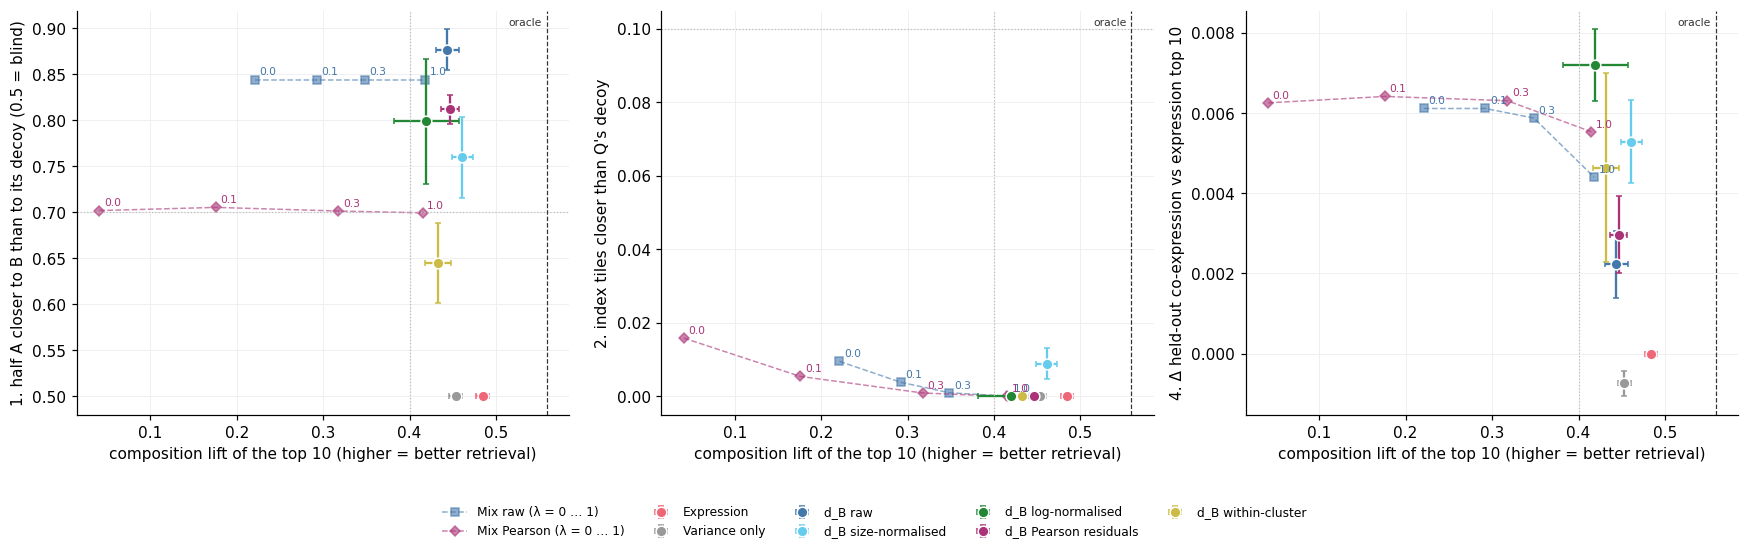

In [6]:
COL = {"Expression": "#EE6677", "Variance only": "#999999", "d_B raw": "#4477AA", "d_B size-normalised": "#66CCEE",
       "d_B log-normalised": "#228833", "d_B Pearson residuals": "#AA3377", "d_B within-cluster": "#CCBB44"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (tx, ty) in zip(axes, [("composition lift", "half win"), ("composition lift", "decoy rank"),
                               ("composition lift", "co-expression")]):
    for fam, color, marker in (("Mix raw", "#4477AA", "s"), ("Mix Pearson", "#AA3377", "D")):
        ms = [m for m in METHODS if m.startswith(fam)]
        xs = [seed_means[f"{tx} | {m}"].mean() for m in ms]
        ys = [seed_means[f"{ty} | {m}"].mean() - (seed_means["co-expression | Expression"].mean()
              if ty == "co-expression" else 0) for m in ms]
        ax.plot(xs, ys, "--", marker=marker, color=color, alpha=0.6, lw=1, ms=5, label=f"{fam} (λ = 0 … 1)")
        for x, y, l in zip(xs, ys, LAMBDAS):
            ax.annotate(f"{l}", (x, y), fontsize=7, color=color, xytext=(3, 3), textcoords="offset points")
    for m, color in COL.items():
        x = seed_means[f"{tx} | {m}"]
        y = seed_means[f"{ty} | {m}"] - (seed_means["co-expression | Expression"] if ty == "co-expression" else 0)
        ax.errorbar(x.mean(), y.mean(), xerr=x.std(), yerr=y.std(), fmt="o", ms=7, color=color, mec="white",
                    capsize=2, label=m)
    if ty in PASS:
        ax.axhline(PASS[ty], color="#bbbbbb", lw=0.8, ls=":")
    ax.axvline(PASS["composition lift"], color="#bbbbbb", lw=0.8, ls=":")
    ax.axvline(oracle.mean(), color="#333333", lw=0.8, ls="--")
    ax.annotate("oracle", (oracle.mean(), 1), xycoords=("data", "axes fraction"), fontsize=7, color="#333333",
                xytext=(-3, -10), textcoords="offset points", ha="right")
    ax.set_xlabel("composition lift of the top 10 (higher = better retrieval)")
    ax.set_ylabel({"half win": "1. half A closer to B than to its decoy (0.5 = blind)",
                   "decoy rank": "2. index tiles closer than Q's decoy",
                   "co-expression": "4. Δ held-out co-expression vs expression top 10"}[ty])
    ax.grid(color="#eeeeee", lw=0.6)
    ax.set_axisbelow(True)
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=5, frameon=False, fontsize=8)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

## Reading the results (Slurm job 24261, 1 Nov; breast, cap 200, seeds 0–4)

**No variant passes.** Every one fails on decoy rank (test 2: at most 1.6 % against 10 %).

- **d_B already sees co-expression when expression is held fixed.** Against the size-preserving decoy (identical means
  and variances, cell size kept) raw d_B wins 0.88; expression and variance-only are at 0.50 by construction. The other
  transforms win less (0.65–0.81); the mixes' win does not depend on λ, because the decoy keeps the variances exactly.
- **In open search co-expression does not move the neighbours, under any variant.** The decoy is closer than ≥ 98 % of
  real tiles even for correlation only (1 %, against 10–24 % with the 30 Oct within-type decoy, which also destroyed
  cell size). Expression differences between real tiles are far larger than co-expression differences; making d_B
  less variance-driven does not change that.
- **Composition is compressed by the tile size.** The oracle ceiling is 0.559; expression reaches 87 % of it and the
  d_B variants 75–82 % (raw 79 %, size-normalised 82 %). Composition separates distances that stop following expression
  (the low-λ mixes, 0.04–0.35), not the d_B variants from one another.
- **Re-ranking expression's 50 nearest** (test 4): every covariance distance picks tiles with more held-out
  co-expression than expression's top 10 (expression gains +0.005 over random). Raw d_B +0.002, size-normalised +0.005,
  log-normalised +0.007 (the most, at a composition cost), the mixes about +0.006.
- **Variance dominance** (test 5): raw d_B follows the variance distance at ρ 0.97; the count transforms bring it to
  about 0.6, without making co-expression decide open search.

**Bottom line.** No evidence for changing the metric. The claim the data support is co-expression *where expression is
held fixed or already matched* (test 1, re-ranking, gene-set signatures), not a better open-search ranking.
Size-normalised d_B is the best trade-off if the metric were ever revisited (better composition, 2.4× the re-ranking
co-expression), but it loses on test 1 and is a change to the frozen method.

**Caveats.** One section, one tile size; per-tile co-expression is noisy at ~67 cells; the decoys are synthetic.